In [162]:
import sys
sys.path.append("..")
from data.db import get_connection, release_connection
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [522]:
def get_spy():
    conn = get_connection()
    df = pd.read_sql("select * from stock_tick_data where datetime > '2019-01-01'::timestamp AND symbol = 'SPY';", conn)
    df = df.sort_values("datetime")
    df.index = df["datetime"]
    release_connection(conn=conn)
    return df
    
tick_data = get_spy()
tick_data = tick_data.groupby(tick_data.index).agg(
    price=("price",'last'),
    volume=("volume",'sum')
)
tick_data["datetime"] = tick_data.index

/var/folders/89/jcq7r95d3csfd9ls92wxdzj40000gn/T/ipykernel_78811/936779290.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql("select * from stock_tick_data where datetime > '2019-01-01'::timestamp AND symbol = 'SPY';", conn)


In [525]:
def agg(df):
    out = df.groupby("group").agg(
        datetime=("datetime", "last"),
        open=("price", "first"),
        close=("price", "last"),
        low=("price", "min"),
        high=("price", "max"),
        volume=("volume", "sum")
    ).set_index("datetime", drop=True)
    return out

def tick_bar(df, threshold):
    df = df.reset_index(drop=True)
    df = df.assign(group = df.index//threshold)
    return agg(df)

def volume_bar(df, threshold):
    assert df["volume"].sum() > 0
    df = df.dropna(axis=0)
    df = df.assign(group = df["volume"].cumsum()//threshold)
    return agg(df)

def dollar_bar(df, threshold):
    df["pv"] = df["price"]*df["volume"]
    assert df["pv"].sum() > 0
    df = df.dropna(axis=0)
    df = df.assign(group = df["pv"].cumsum()//threshold)
    return agg(df)


In [519]:
time_df = tick_data.resample("min")["price"].ohlc()

In [539]:
tick_df = tick_bar(tick_data, threshold=10)
volume_df = volume_bar(tick_data, threshold=4000)
dollar_df = dollar_bar(tick_data, threshold=500000)

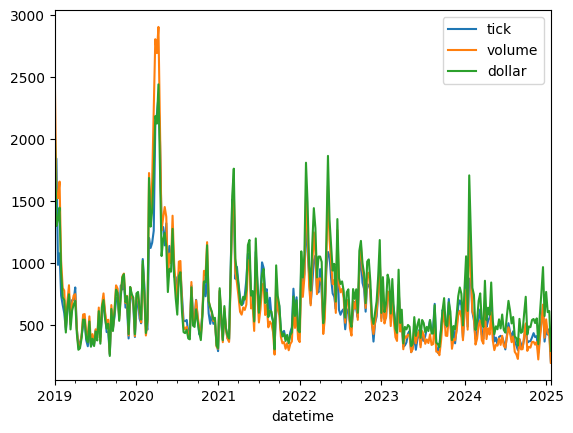

In [540]:
time_cnt = time_df.resample('W')["close"].count()
tick_cnt = tick_df.resample('W')["close"].count()
volume_cnt = volume_df.resample('W')["close"].count()
dollar_cnt = dollar_df.resample('W')["close"].count()
tick_cnt.plot(label="tick")
volume_cnt.plot(label="volume")
dollar_cnt.plot(label="dollar")
plt.legend()

In [541]:
print(
    time_cnt.mean(), time_cnt.std(), "\n",
    tick_cnt.mean(), tick_cnt.std(),"\n",
    volume_cnt.mean(), volume_cnt.std(),"\n",
    dollar_cnt.mean(), dollar_cnt.std()    
)


1640.0599369085173 207.4837637478734 
 647.2870662460568 303.96047626238675 
 664.589905362776 395.21760024490993 
 719.9369085173502 345.438891343227


In [544]:
time_ret = time_df.close.apply(np.log).diff().dropna()
tick_ret = tick_df.close.apply(np.log).diff().dropna()
volume_ret = volume_df.close.apply(np.log).diff().dropna()
dollar_ret = dollar_df.close.apply(np.log).diff().dropna()

In [545]:
iterator = lambda func:[func(i) for i in range(1, 7)]
pd.DataFrame({
    'time':iterator(time_ret.autocorr),
    'tick':iterator(tick_ret.autocorr),
    'vol':iterator(volume_ret.autocorr),
    'dollar':iterator(dollar_ret.autocorr)
})

,time,tick,vol,dollar
0,-0.017764,-0.002488,-0.052112,-0.062349
1,-0.009038,0.001743,-0.001961,0.007074
2,0.003303,0.002427,0.004389,0.002725
3,0.002026,-0.003942,-0.004347,-0.003031
4,-0.006105,-0.018754,-0.004388,-0.002121
5,-0.001164,-0.001279,-0.001590,0.012680


In [546]:
pd.Series({
    'time':time_ret[3:].resample("1M").var().var(),
    'tick':tick_ret[3:].resample("1M").var().var(),
    'volume':volume_ret[3:].resample("1M").var().var(),
    'dollar':dollar_ret[3:].resample("1M").var().var(),
})

/var/folders/89/jcq7r95d3csfd9ls92wxdzj40000gn/T/ipykernel_78811/2382724659.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  'time':time_ret[3:].resample("1M").var().var(),
/var/folders/89/jcq7r95d3csfd9ls92wxdzj40000gn/T/ipykernel_78811/2382724659.py:3: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  'tick':tick_ret[3:].resample("1M").var().var(),
/var/folders/89/jcq7r95d3csfd9ls92wxdzj40000gn/T/ipykernel_78811/2382724659.py:4: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  'volume':volume_ret[3:].resample("1M").var().var(),
/var/folders/89/jcq7r95d3csfd9ls92wxdzj40000gn/T/ipykernel_78811/2382724659.py:5: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  'dollar':dollar_ret[3:].resample("1M").var().var(),


time      2.387815e-13
tick      1.753929e-12
volume    1.225012e-12
dollar    1.770571e-12
dtype: float64

/var/folders/89/jcq7r95d3csfd9ls92wxdzj40000gn/T/ipykernel_78811/2546481211.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  time_ret.resample("1M").var().plot(label="time")
/var/folders/89/jcq7r95d3csfd9ls92wxdzj40000gn/T/ipykernel_78811/2546481211.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  tick_ret.resample("1M").var().plot(label="tick")
/var/folders/89/jcq7r95d3csfd9ls92wxdzj40000gn/T/ipykernel_78811/2546481211.py:3: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  volume_ret.resample("1M").var().plot(label="volume")
/var/folders/89/jcq7r95d3csfd9ls92wxdzj40000gn/T/ipykernel_78811/2546481211.py:4: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  dollar_ret.resample("1M").var().plot(label="dollar")


<Axes: xlabel='datetime'>

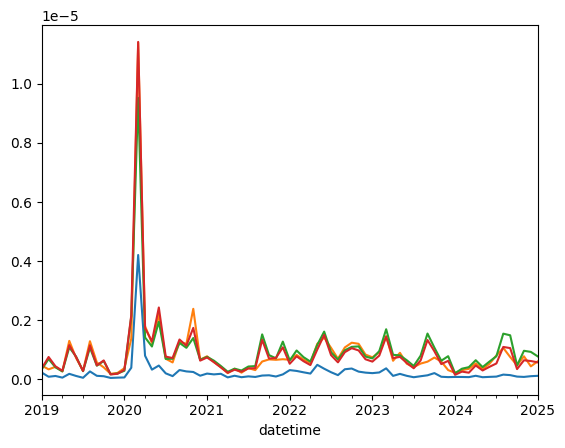

In [547]:
time_ret.resample("1M").var().plot(label="time")
tick_ret.resample("1M").var().plot(label="tick")
volume_ret.resample("1M").var().plot(label="volume")
dollar_ret.resample("1M").var().plot(label="dollar")

13.971050175489333 minutes in average.
2.7045626944853494 minutes in average. (outliers removed)


<Axes: >

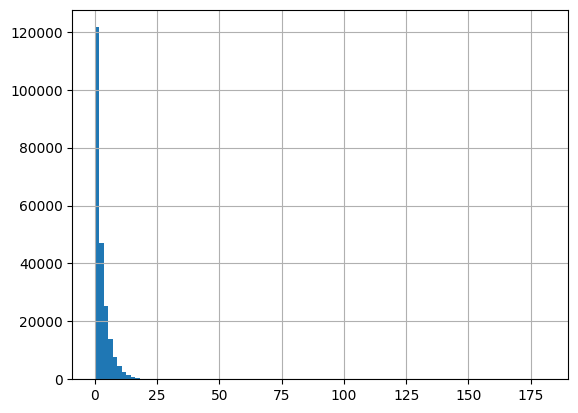

In [549]:
dollar_df = dollar_bar(tick_data, threshold=500000)
periods = dollar_df.index.diff().total_seconds().astype(float).to_series()/60
upThresh = periods.mean() + 1*periods.std()

print("%s minutes in average." % (periods.mean()))
print("%s minutes in average. (outliers removed)" % (periods[periods < upThresh].mean()))
periods[periods < upThresh].hist(bins=100)

In [550]:

def bollingBandCrossCnt(price:pd.Series, window=20, band_width=0.05):
    ma = price.rolling(window=window).mean()
    abs_diff = (price/ma - 1).abs()
    return abs_diff[(abs_diff >= band_width) & (abs_diff.shift(1) < band_width)].index


def getTEvents(gRaw,h): 
    tEvents,sPos,sNeg=[],0,0 
    diff=gRaw.diff()
    for i in diff.index[1:]:
        sPos=max(0,sPos+diff.loc[i])
        sNeg=min(0,sNeg+diff.loc[i])
        if sNeg<-h:
            sNeg=0
            tEvents.append(i) 
        elif sPos>h:
            sPos=0
            tEvents.append(i)
            
    return pd.DatetimeIndex(tEvents)

In [554]:
cnt1 = bollingBandCrossCnt(price=dollar_df["close"], window=20, band_width=0.0001)
cnt2 = getTEvents(gRaw=dollar_df["close"], h=0.05)

cnt1, cnt2

(DatetimeIndex(['2019-01-01 01:11:31', '2019-01-01 01:14:04',
                '2019-01-01 01:28:39', '2019-01-01 01:55:43',
                '2019-01-01 02:00:19', '2019-01-01 02:38:02',
                '2019-01-01 03:09:04', '2019-01-01 03:18:16',
                '2019-01-01 03:21:45', '2019-01-01 03:39:54',
                ...
                '2025-01-23 02:21:08', '2025-01-23 02:30:53',
                '2025-01-23 02:36:43', '2025-01-23 02:44:28',
                '2025-01-23 03:00:27', '2025-01-23 03:42:11',
                '2025-01-23 04:18:54', '2025-01-23 04:26:19',
                '2025-01-23 04:30:46', '2025-01-23 04:32:53'],
               dtype='datetime64[ns]', name='datetime', length=11118, freq=None),
 DatetimeIndex(['2019-01-01 00:01:22', '2019-01-01 00:03:39',
                '2019-01-01 00:05:02', '2019-01-01 00:08:02',
                '2019-01-01 00:11:07', '2019-01-01 00:14:30',
                '2019-01-01 00:21:36', '2019-01-01 00:25:02',
                '2019-01-01 0

In [479]:
# dollar_df["close"][:1000].plot(use_index=False)
# dollar_df[cnt2]["close"]

dollar_df[cnt2]

KeyError: "None of [DatetimeIndex(['1970-01-01 00:00:00.000000002',\n               '1970-01-01 00:00:00.000000004',\n               '1970-01-01 00:00:00.000000005',\n               '1970-01-01 00:00:00.000000007',\n               '1970-01-01 00:00:00.000000009',\n               '1970-01-01 00:00:00.000000016',\n               '1970-01-01 00:00:00.000000024',\n               '1970-01-01 00:00:00.000000030',\n               '1970-01-01 00:00:00.000000031',\n               '1970-01-01 00:00:00.000000034',\n               ...\n               '1970-01-01 00:00:00.000256180',\n               '1970-01-01 00:00:00.000256185',\n               '1970-01-01 00:00:00.000256187',\n               '1970-01-01 00:00:00.000256197',\n               '1970-01-01 00:00:00.000256198',\n               '1970-01-01 00:00:00.000256200',\n               '1970-01-01 00:00:00.000256201',\n               '1970-01-01 00:00:00.000256204',\n               '1970-01-01 00:00:00.000256206',\n               '1970-01-01 00